# 06 - Clustering Toxic Comments (K-Means + Hierarchical)
**Lab link:** Exp 14 (K-Means), Exp 15 (Hierarchical clustering)

**Is there a natural clustering angle here?** Yes, a modest one. Moderators don't only need "toxic or not"; grouping toxic comments into **themes** (e.g. profanity-heavy, personal insults, threats, hate) can help them review similar comments together. This is *exploratory only* - clustering is **not** part of the final prediction pipeline.

We cluster only the toxic comments (any label = 1), using the 100-dim SVD features from notebook 02.

In [1]:
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)

LABELS = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]
RAW = Path("../data/raw")
PROC = Path("../data/processed")     # cleaned text + feature matrices made in notebook 02
MODELS = Path("../models")
ASSETS = Path("../assets")
for folder in (PROC, MODELS, ASSETS):
    folder.mkdir(exist_ok=True)

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram
import scipy.sparse as sp

train_clean = pd.read_csv(PROC / "train_clean.csv")
train_clean["clean_text"] = train_clean["clean_text"].fillna("")
X_svd = np.load(PROC / "X_train_svd.npy")
X_tfidf = sp.load_npz(PROC / "X_train_tfidf.npz")

toxic_mask = (train_clean[LABELS].sum(axis=1) > 0).values
Xt = X_svd[toxic_mask]
texts_t = train_clean.loc[toxic_mask, "clean_text"].reset_index(drop=True)
labels_t = train_clean.loc[toxic_mask, LABELS].reset_index(drop=True)
print("Toxic comments to cluster:", Xt.shape)

Toxic comments to cluster: (13004, 100)


## 1. Choosing K (elbow + silhouette)
* **Inertia** (elbow): total distance of points to their cluster centre - always drops as K grows; we look for the "bend".
* **Silhouette score**: how well separated the clusters are (higher is better, range -1 to 1). Computed on a 4,000-comment sample to save time.

K =  2 | inertia       3096 | silhouette 0.1277


K =  3 | inertia       2961 | silhouette 0.0700


K =  4 | inertia       2891 | silhouette 0.0751


K =  5 | inertia       2836 | silhouette 0.0662


K =  6 | inertia       2786 | silhouette 0.0612


K =  7 | inertia       2763 | silhouette 0.0480


K =  8 | inertia       2708 | silhouette 0.0447


K =  9 | inertia       2684 | silhouette 0.0539


K = 10 | inertia       2647 | silhouette 0.0427


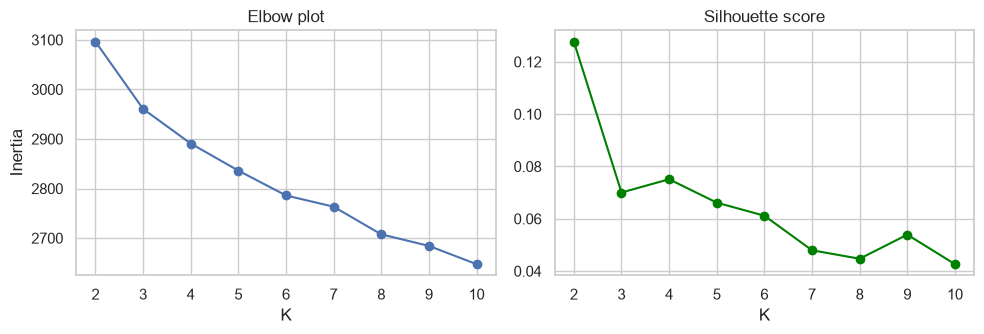

In [2]:
rng = np.random.RandomState(42)
sil_idx = rng.choice(len(Xt), size=min(4000, len(Xt)), replace=False)

ks = list(range(2, 11))
inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=3, random_state=42).fit(Xt)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(Xt[sil_idx], km.labels_[sil_idx]))
    print(f"K = {k:2d} | inertia {km.inertia_:10.0f} | silhouette {silhouettes[-1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(ks, inertias, marker="o"); axes[0].set_title("Elbow plot"); axes[0].set_xlabel("K"); axes[0].set_ylabel("Inertia")
axes[1].plot(ks, silhouettes, marker="o", color="green"); axes[1].set_title("Silhouette score"); axes[1].set_xlabel("K")
plt.tight_layout()
plt.savefig(ASSETS / "kmeans_elbow_silhouette.png", dpi=150)
plt.show()

In [3]:
# Choose K: highest silhouette among K >= 3 (K = 2 is usually just "short vs long" and not useful for moderators)
candidates = {k: s for k, s in zip(ks, silhouettes) if k >= 3}
best_k = max(candidates, key=candidates.get)
print("Chosen K =", best_k, "(silhouette", round(candidates[best_k], 4), ")")

Chosen K = 4 (silhouette 0.0751 )


Silhouette scores for text are usually low (clusters overlap in language), so we pick K using silhouette *and* check that the clusters are **interpretable** below.

## 2. K-Means result: what is inside each cluster?

In [4]:
km = KMeans(n_clusters=best_k, n_init=5, random_state=42).fit(Xt)
cluster = km.labels_

# top words per cluster, using the WORD part of TF-IDF (first 10,000 columns)
union = joblib.load(MODELS / "tfidf_union_series.pkl")
word_names = union.transformer_list[0][1].get_feature_names_out()
X_toxic_word = X_tfidf[toxic_mask][:, :len(word_names)]

rows = []
for c in range(best_k):
    members = np.where(cluster == c)[0]
    mean_vec = np.asarray(X_toxic_word[members].mean(axis=0)).ravel()
    top_words = ", ".join(word_names[np.argsort(mean_vec)[::-1][:8]])
    rows.append({"cluster": c, "size": len(members), "top words": top_words})
pd.DataFrame(rows)

,cluster,size,top words
0,0,592,"you re, re, you, and, fucking, the, to, your"
1,1,6007,"you, your, is, are, my, and, you are, the"
2,2,4351,"you, and, the, to, of, is, that, are"
3,3,2054,"fuck, fucking, fuck you, you, fuck off, bitch, shit, off"


,size,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,592,96.3,10.8,51.5,2.7,59.3,8.4
1,6007,95.2,6.6,45.2,3.4,45.1,9.0
2,4351,89.5,2.7,38.8,1.7,36.2,5.6
3,2054,99.9,34.2,98.8,4.3,80.4,13.8


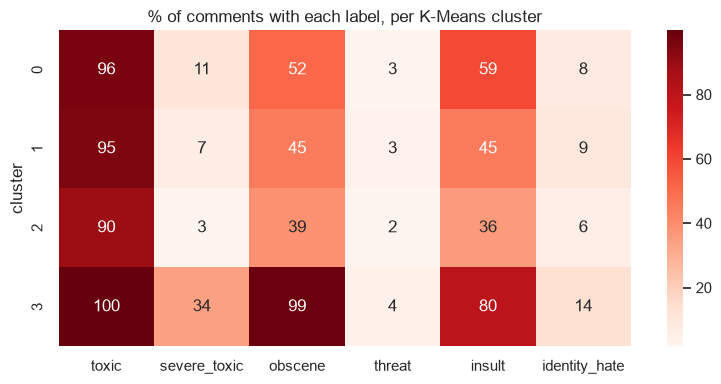

In [5]:
# share of each label inside each cluster (%)
profile = labels_t.groupby(cluster).mean().round(3) * 100
profile.insert(0, "size", pd.Series(cluster).value_counts().sort_index())
display(profile)

plt.figure(figsize=(8, 4))
sns.heatmap(profile[LABELS], annot=True, fmt=".0f", cmap="Reds")
plt.title("% of comments with each label, per K-Means cluster")
plt.ylabel("cluster")
plt.tight_layout()
plt.savefig(ASSETS / "kmeans_cluster_profile.png", dpi=150)
plt.show()

**How to read it:** if a cluster has a high `threat` or `identity_hate` percentage, it is a theme moderators would want to review first. Clusters that mostly differ by *topic or length* rather than toxicity type are a sign that K-Means is picking up writing style, which we state honestly as a limitation.

## 3. Hierarchical clustering (Exp 15)
Hierarchical (agglomerative) clustering is **O(n^2)** in memory, so we run it on a random sample of **1,000** toxic comments. We use Ward linkage, then compare with K-Means.

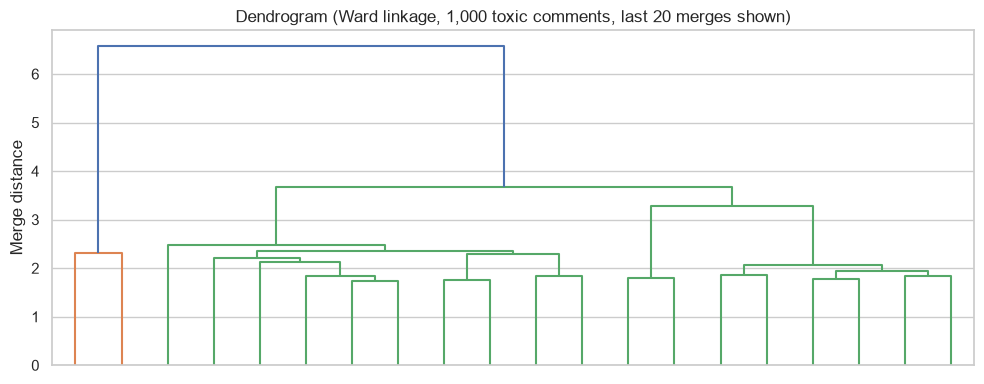

In [6]:
small_idx = rng.choice(len(Xt), size=min(1000, len(Xt)), replace=False)
Xs = Xt[small_idx]

Z = linkage(Xs, method="ward")
plt.figure(figsize=(10, 4))
dendrogram(Z, truncate_mode="lastp", p=20, no_labels=True)
plt.title("Dendrogram (Ward linkage, 1,000 toxic comments, last 20 merges shown)")
plt.ylabel("Merge distance")
plt.tight_layout()
plt.savefig(ASSETS / "hierarchical_dendrogram.png", dpi=150)
plt.show()

In [7]:
agg = AgglomerativeClustering(n_clusters=best_k, linkage="ward").fit(Xs)
print("Hierarchical cluster sizes:", np.bincount(agg.labels_))
print("K-Means cluster sizes on the same 1,000 comments:", np.bincount(km.predict(Xs)))

# how similar are the two groupings? (Adjusted Rand Index: 1 = identical, 0 = random)
from sklearn.metrics import adjusted_rand_score
print("Adjusted Rand Index between the two methods:", round(adjusted_rand_score(agg.labels_, km.predict(Xs)), 3))

Hierarchical cluster sizes: [474 172 306  48]
K-Means cluster sizes on the same 1,000 comments: [ 45 450 342 163]
Adjusted Rand Index between the two methods: 0.469


## Conclusion
* K-Means gave **K clusters of toxic comments** (K chosen with elbow + silhouette) and we inspected their top words and label mix.
* Hierarchical clustering on a small sample shows the merge structure; the Adjusted Rand Index tells how much it agrees with K-Means.
* Clustering is an **exploratory add-on** (theme grouping for moderators); our deployed system uses the supervised model + 3-tier decision engine.